# Batch Normalization: How It Works, and How It Tames Internal Covariate Shift

The previous notebook (*Internal Covariate Shift: What It Is, How to Measure It, and What It Does (and Doesn't) Explain*) showed that **a layer's input distribution drifts during training**, that BatchNorm (BN) removes most of that drift, and that the story of *why* BN helps is more subtle than "it removes ICS". This notebook opens the box: **what exactly does BatchNorm compute, why does that pin down each layer's input, and what else does it change?**

```
 plain block:        h_{j-1} --> [ Linear ] --> [ tanh ] --> h_j

 BatchNorm block:    h_{j-1} --> [ Linear ] --> [ BatchNorm ] --> [ tanh ] --> h_j
                                       z        z_hat = (z - mu_B) / sqrt(var_B + eps)
                                                out   = gamma * z_hat + beta
                                       mu_B, var_B: mean / variance of z over the *mini-batch*
                                       gamma, beta: learned, one pair per unit
```

**What you will do**

1. Implement BatchNorm from scratch and check it against `nn.BatchNorm1d` (forward pass, gradients, running statistics)
2. See what it does to one layer's pre-activations and why that matters for `tanh`
3. Show, with a controlled experiment, that BN makes a layer's input **independent of what the earlier layers do** (the "ICS fix", in its purest form)
4. Show a second, less-advertised property: BN makes a layer **scale-invariant**, which changes how gradients behave
5. Train deep networks with and without BN and watch the drift disappear, then see what BN buys in training speed, learning-rate tolerance and robustness to bad initialization
6. Understand the **train / eval split** (batch statistics vs running statistics) and the price BN pays for depending on the batch
7. Put the ICS claim back in perspective

Everything runs on CPU in a few minutes.

## 0. Setup

In [1]:
import copy
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 0


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)          # tiny networks run fastest single-threaded on CPU
print("torch", torch.__version__)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# Same data and split as the ICS notebook: scikit-learn digits (8x8 images, 10 classes)
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)
yd = digits.target.astype(np.int64)
X_tr, X_rest, y_tr, y_rest = train_test_split(Xd, yd, train_size=1000, stratify=yd, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, train_size=400, stratify=y_rest, random_state=SEED)
print(f"train={len(X_tr)}  val={len(X_va)}  test={len(X_te)}")

Xtr_t, ytr_t = torch.tensor(X_tr), torch.tensor(y_tr)
Xva_t, yva_t = torch.tensor(X_va), torch.tensor(y_va)
PROBE_X, PROBE_Y = Xtr_t[:256], ytr_t[:256]       # a fixed batch used to *observe* networks
loss_fn = nn.CrossEntropyLoss()

torch 2.15.0+cu132
train=1000  val=400  test=397


## 1. The BatchNorm operation, from scratch

For a layer with pre-activations `z` of shape `[batch, features]`, BatchNorm does the following **per feature**:

1. Compute the mini-batch mean and variance: `mu_B = mean(z)`, `var_B = mean((z - mu_B)^2)`
2. Standardize: `z_hat = (z - mu_B) / sqrt(var_B + eps)`. Now each feature has mean 0 and variance 1 *over the batch*
3. Re-scale and re-shift with **learned** parameters: `out = gamma * z_hat + beta`

Step 3 matters: forcing every feature to exactly mean 0 and variance 1 would limit what the layer can represent (for `sigmoid` it would confine units to the near-linear region). `gamma` and `beta` let the network choose any mean and scale it likes, but, as we will see, they are **two free parameters per unit** rather than a quantity entangled with every earlier weight.

At **test time** there may be a single example, so there is no batch to take statistics from. BN therefore also keeps **running averages** of `mu_B` and `var_B` during training (`running = (1 - m) * running + m * batch_stat`, momentum `m = 0.1` by default) and uses those in `eval()` mode.

Below is a complete implementation, in about 15 lines.

In [2]:
class ScratchBatchNorm1d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.gamma = nn.Parameter(torch.ones(num_features))
        self.beta = nn.Parameter(torch.zeros(num_features))
        self.register_buffer("running_mean", torch.zeros(num_features))
        self.register_buffer("running_var", torch.ones(num_features))

    def forward(self, x):
        if self.training:
            mu = x.mean(0)
            var = x.var(0, unbiased=False)            # the *biased* variance normalizes the batch ...
            with torch.no_grad():
                n = x.shape[0]
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mu)
                # ... but PyTorch stores the *unbiased* variance in the running estimate
                self.running_var.mul_(1 - self.momentum).add_(self.momentum * var * n / (n - 1))
        else:
            mu, var = self.running_mean, self.running_var
        x_hat = (x - mu) / torch.sqrt(var + self.eps)
        return self.gamma * x_hat + self.beta

### 1a. Check it against PyTorch

We compare against `nn.BatchNorm1d` in float64 with random `gamma`/`beta`: the forward output, the gradients with respect to the input, `gamma` and `beta` (the backward pass must differentiate *through* the batch statistics, and autograd does that for us), the running statistics after 20 further batches, and the `eval()`-mode output.

In [3]:
torch.manual_seed(0)
C = 5
mine, ref = ScratchBatchNorm1d(C).double(), nn.BatchNorm1d(C).double()
with torch.no_grad():
    g, b = torch.randn(C).double() + 1.5, torch.randn(C).double()
    mine.gamma.copy_(g); mine.beta.copy_(b); ref.weight.copy_(g); ref.bias.copy_(b)

x1 = (torch.randn(32, C) * 3 + 2).double().requires_grad_()
x2 = x1.detach().clone().requires_grad_()
w = torch.randn(32, C).double()                      # arbitrary upstream gradient
o1, o2 = mine(x1), ref(x2)
(o1 * w).sum().backward(); (o2 * w).sum().backward()

rows = [("forward output", (o1 - o2).abs().max()),
        ("grad wrt input", (x1.grad - x2.grad).abs().max()),
        ("grad wrt gamma", (mine.gamma.grad - ref.weight.grad).abs().max()),
        ("grad wrt beta", (mine.beta.grad - ref.bias.grad).abs().max())]

with torch.no_grad():
    for _ in range(20):
        xb = (torch.randn(32, C) * 3 + 2).double()
        mine(xb); ref(xb)
rows += [("running mean", (mine.running_mean - ref.running_mean).abs().max()),
         ("running var", (mine.running_var - ref.running_var).abs().max())]

mine.eval(); ref.eval()
with torch.no_grad():
    xt = (torch.randn(7, C) * 3 + 2).double()
    rows.append(("eval-mode output", (mine(xt) - ref(xt)).abs().max()))

print(f"{'quantity':<20} {'max |difference|':>18}")
for name, d in rows:
    print(f"{name:<20} {d.item():>18.2e}")
print("\nOutput stats over the batch (train mode, gamma=1.5-ish, beta=random):")
print("  per-feature mean of z_hat:", ((o1 - mine.beta) / mine.gamma).mean(0).detach().numpy().round(6))
print("  per-feature std  of z_hat:", ((o1 - mine.beta) / mine.gamma).std(0, unbiased=False).detach().numpy().round(4))

quantity               max |difference|
forward output                 8.88e-16
grad wrt input                 6.66e-16
grad wrt gamma                 3.55e-15
grad wrt beta                  0.00e+00
running mean                   0.00e+00
running var                    1.78e-15
eval-mode output               8.88e-16

Output stats over the batch (train mode, gamma=1.5-ish, beta=random):
  per-feature mean of z_hat: [0. 0. 0. 0. 0.]
  per-feature std  of z_hat: [1. 1. 1. 1. 1.]


**What to notice.** Every difference is at the level of float64 round-off (below `1e-14`), so the from-scratch layer is the same function as PyTorch's, including its gradients. Two details worth remembering: the normalization uses the *biased* batch variance while the running estimate stores the *unbiased* one, and the backward pass has to differentiate through `mu_B` and `var_B` (each output depends on every example in the batch), which autograd does automatically. After standardization every feature has mean 0 and standard deviation 1 over the batch, exactly.

## 2. What BN does to one layer

Imagine that earlier layers have pushed a layer's pre-activations `z` far from where `tanh` is well-behaved: the unit has a large positive mean and a wide spread. This is exactly what the ICS notebook saw in the plain network (units drifting to saturation). We build such a layer artificially and look at one unit across a batch of 512 digits, then count how many units are saturated across the whole layer.

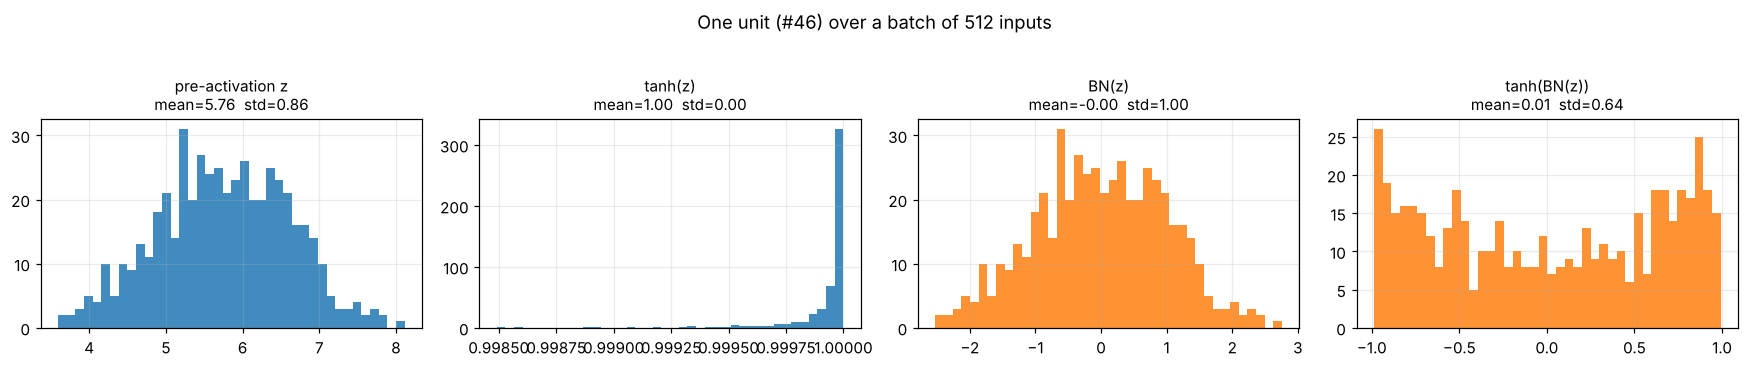

Fraction of ALL 64 units x 512 samples with |tanh| > 0.97 (saturated):
   without BN: 37.0%      with BN: 3.0%


In [4]:
set_seed()
lin = nn.Linear(64, 64)
with torch.no_grad():
    nn.init.xavier_uniform_(lin.weight, gain=3.0)         # large weights ...
    lin.bias.copy_(torch.randn(64) * 2.0)                 # ... and per-unit offsets
Z = lin(Xtr_t[:512]).detach()                             # pre-activations [512, 64]
Zbn = F.batch_norm(Z, None, None, training=True)          # BN with gamma=1, beta=0
u = int(Z.mean(0).abs().argmax())                         # the most displaced unit

panels = [("pre-activation z", Z[:, u]), ("tanh(z)", torch.tanh(Z[:, u])),
          ("BN(z)", Zbn[:, u]), ("tanh(BN(z))", torch.tanh(Zbn[:, u]))]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (title, v) in zip(axes, panels):
    ax.hist(v.numpy(), bins=40, color="C0" if "BN" not in title else "C1", alpha=0.85)
    ax.set_title(f"{title}\nmean={v.mean():.2f}  std={v.std():.2f}", fontsize=10)
plt.suptitle(f"One unit (#{u}) over a batch of 512 inputs", y=1.03)
plt.tight_layout(); plt.show()

sat = lambda h: (h.abs() > 0.97).float().mean().item()
print(f"Fraction of ALL 64 units x 512 samples with |tanh| > 0.97 (saturated):")
print(f"   without BN: {sat(torch.tanh(Z)):.1%}      with BN: {sat(torch.tanh(Zbn)):.1%}")

**What to notice.** This unit has a mean of 5.8 and a spread of only 0.86, so `tanh` squashes **all** of its 512 outputs into the range 0.9985 to 1.0: the unit carries essentially no information, and because `tanh'(z)` is nearly zero there, almost no gradient flows back through it either. After BN the same unit has mean 0 and standard deviation 1, uses the full range of `tanh`, and has a healthy derivative. Across the whole layer, 37% of the activations are saturated without BN, against 3% with it (that remaining 3% is just the tail of a standard normal beyond about 2.1, where `|tanh| > 0.97`).

This is the same failure the ICS notebook saw in the plain network: units drifting into saturation as earlier layers change.

## 3. Why BN pins a layer's input: invariance to what earlier layers do

Here is the cleanest way to see how BN deals with internal covariate shift. Take **two layers**. Layer 1 turns the data into `h1`, and `h1` is layer 2's input. During training, layer 1's parameters keep changing. We simulate three kinds of change, applied to layer 1's weights `W` and bias `b`:

- **(i) rescale** the weights: `W -> s * W`
- **(ii) shift** the bias: `b -> b + delta * direction`
- **(iii) perturb** the weights randomly: `W -> W + eps * noise` (a change in the *direction* of each unit's weight vector, not just its size)

After each change we look at the statistics of layer 2's input `h1 = tanh(z)` (plain) or `h1 = tanh(BN(z))` (BN), over a fixed batch: the average magnitude of the unit means, and the average unit standard deviation. If layer 2's input distribution is independent of layer 1's changes, these curves are flat.

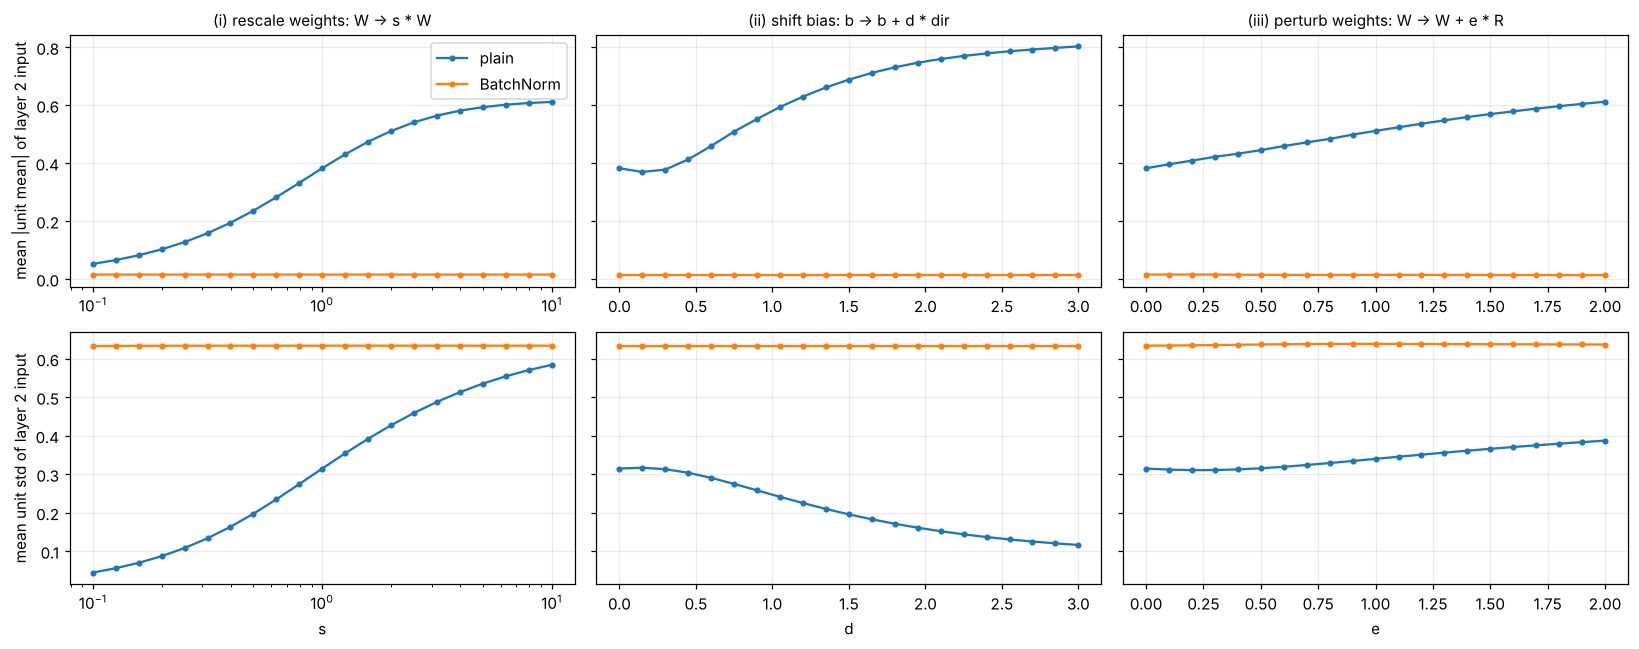

Largest change of any BatchNorm curve over all three sweeps: 4.7e-03
max |BN(Wx) - BN(7.3*Wx + bias)| = 2.0e-04


In [5]:
g = torch.Generator().manual_seed(0)
bound = np.sqrt(6.0 / (64 + 64))
W0 = (torch.rand(64, 64, generator=g) * 2 - 1) * bound * nn.init.calculate_gain("tanh")
R = torch.randn(64, 64, generator=g) * W0.std()          # random perturbation with the same scale as W0
b_dir = torch.randn(64, generator=g)


def layer2_input(W, b, use_bn):
    z = PROBE_X @ W.T + b
    if use_bn:
        z = F.batch_norm(z, None, None, training=True)
    return torch.tanh(z)


def stats(h):
    return h.mean(0).abs().mean().item(), h.std(0).mean().item()


sweeps = {
    "(i) rescale weights: W -> s * W":        (torch.logspace(-1, 1, 21), lambda s: (W0 * s, torch.zeros(64)), "s"),
    "(ii) shift bias: b -> b + d * dir":      (torch.linspace(0, 3, 21),  lambda d: (W0, d * b_dir), "d"),
    "(iii) perturb weights: W -> W + e * R": (torch.linspace(0, 2, 21),  lambda e: (W0 + e * R, torch.zeros(64)), "e"),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharey="row")
worst = 0.0
for col, (title, (grid, make, sym)) in enumerate(sweeps.items()):
    res = {use_bn: np.array([stats(layer2_input(*make(v), use_bn)) for v in grid]) for use_bn in (False, True)}
    for use_bn, label in ((False, "plain"), (True, "BatchNorm")):
        axes[0, col].plot(grid, res[use_bn][:, 0], marker="o", ms=3, label=label)
        axes[1, col].plot(grid, res[use_bn][:, 1], marker="o", ms=3, label=label)
    worst = max(worst, np.ptp(res[True], axis=0).max())
    axes[0, col].set_title(title, fontsize=10); axes[1, col].set_xlabel(sym)
    if col == 0: axes[0, col].set_xscale("log"), axes[1, col].set_xscale("log")
axes[0, 0].set_ylabel("mean |unit mean| of layer 2 input"); axes[1, 0].set_ylabel("mean unit std of layer 2 input")
axes[0, 0].legend()
plt.tight_layout(); plt.show()
print(f"Largest change of any BatchNorm curve over all three sweeps: {worst:.1e}")

# the exact identity behind panels (i) and (ii): BN(s * W x + b) == BN(W x)   (for s > 0)
z_a = F.batch_norm(PROBE_X @ W0.T, None, None, training=True)
z_b = F.batch_norm(PROBE_X @ (7.3 * W0).T + 5.0 * b_dir, None, None, training=True)
print(f"max |BN(Wx) - BN(7.3*Wx + bias)| = {(z_a - z_b).abs().max():.1e}")

**What to notice.** In the plain network, layer 2's input is at the mercy of layer 1: simply rescaling layer 1's weights moves the average unit standard deviation from about 0.04 to 0.58 and the average unit mean from 0.05 to 0.61, shifting a bias changes the picture just as much, and random changes to the weight directions drift the statistics steadily. This is internal covariate shift in its purest form: **whatever layer 1 does, layer 2's input distribution moves.**

With BatchNorm the curves are flat. The largest change anywhere is below 0.005 (it comes from `eps` when the weights are scaled down to `s = 0.1`, and from the *shape* of the distribution changing slightly in panel iii). The identity in the last line shows why for panels i and ii: `BN(s*Wx + b) = BN(Wx)` because the batch mean removes `b` and the batch standard deviation removes `s` (the `1e-4` residual is `eps` and float32 rounding). Panel iii is the general case: BN fixes the first two moments of the pre-activation whatever the weights are, so layer 2's input statistics are set by `gamma` and `beta` and by nothing upstream.

Two honest qualifications. First, "pinned" refers to the **mean and variance**; BN does not freeze the full shape of the distribution (the slight rise in panel iii). Second, `gamma` and `beta` are learned and *can* move these statistics, but now through two parameters per unit that the optimizer controls directly, rather than through every upstream weight at once.

## 4. A deep network, and a second property: scale invariance

Now the networks we will train. Same family as the ICS notebook: an MLP with 8 hidden layers of 64 `tanh` units. The BN variant uses `Linear (no bias) -> BatchNorm -> tanh`: the bias is dropped because BN subtracts the batch mean, so a bias in front of it would be cancelled exactly (section 3, panel ii).

`init_gain` multiplies the usual Xavier-`tanh` initialization of the hidden layers, so we can later ask how sensitive each network is to a badly scaled initialization.

In [6]:
class DeepMLP(nn.Module):
    def __init__(self, norm="none", depth=8, width=64, in_dim=64, out_dim=10, init_gain=1.0):
        super().__init__()
        blocks, d = [], in_dim
        for _ in range(depth):
            layers = [nn.Linear(d, width, bias=(norm != "bn"))]
            if norm == "bn":
                layers.append(nn.BatchNorm1d(width))
            layers.append(nn.Tanh())
            blocks.append(nn.Sequential(*layers))
            d = width
        self.blocks = nn.ModuleList(blocks)
        self.head = nn.Linear(width, out_dim)
        for blk in self.blocks:
            nn.init.xavier_uniform_(blk[0].weight, gain=nn.init.calculate_gain("tanh") * init_gain)
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)
        for m in self.modules():
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x, return_acts=False):
        hs = [x]                                  # hs[j] = output of block j (hs[0] is the data)
        for blk in self.blocks:
            x = blk(x); hs.append(x)
        out = self.head(x)
        return (out, hs) if return_acts else out


def new_model(norm, seed=0, **kw):
    set_seed(seed)
    return DeepMLP(norm, **kw)


print(new_model("bn"))

DeepMLP(
  (blocks): ModuleList(
    (0-7): 8 x Sequential(
      (0): Linear(in_features=64, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): Tanh()
    )
  )
  (head): Linear(in_features=64, out_features=10, bias=True)
)


### 4a. The training loop

The usual loop, with two additions that only *observe*: every few steps it pushes a fixed batch through a copy of the network and records the mean and spread of each block's output (= the next layer's input), and every epoch it records the norm of one layer's weight matrix. A run whose loss becomes non-finite is stopped and marked as diverged (most failures below instead stall at chance accuracy without ever reaching NaN).

In [7]:
val_loader = DataLoader(TensorDataset(Xva_t, yva_t), batch_size=512)


@torch.no_grad()
def evaluate(model, loader=val_loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        logits = model(xb)
        total += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total / n, correct / n


def fit(model, epochs=15, lr=0.05, momentum=0.9, batch_size=64, seed=0, probe_every=None, wlayer=3):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    h = dict(train_loss=[], val_loss=[], val_acc=[], wnorm=[], probe_steps=[], probe_mu=[], probe_sd=[], diverged=False)
    step = 0
    for _ in range(epochs):
        model.train()
        ep = []
        for xb, yb in loader:
            if probe_every and step % probe_every == 0:
                with torch.no_grad():
                    _, hs = copy.deepcopy(model).train()(PROBE_X, return_acts=True)
                h["probe_steps"].append(step)
                h["probe_mu"].append(np.stack([a.mean(0).numpy() for a in hs[1:]]))     # [blocks, units]
                h["probe_sd"].append(np.stack([a.std(0).numpy() for a in hs[1:]]))
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            if not torch.isfinite(loss):
                h["diverged"] = True
                break
            loss.backward(); opt.step()
            ep.append(loss.item()); step += 1
        if h["diverged"]:
            break
        vl, va = evaluate(model)
        h["train_loss"].append(float(np.mean(ep))); h["val_loss"].append(vl); h["val_acc"].append(va)
        h["wnorm"].append(model.blocks[wlayer][0].weight.norm().item())
    missing = epochs - len(h["val_acc"])                       # pad a diverged run so curves line up
    if missing:
        _, va = evaluate(model)
        h["train_loss"] += [np.nan] * missing; h["val_loss"] += [np.nan] * missing
        h["val_acc"] += [va] * missing; h["wnorm"] += [np.nan] * missing
    return h

### 4b. Scale invariance and what it does to gradients

In section 3 we saw that scaling a preceding weight matrix does not change BN's output. Therefore the **loss itself does not change** when you rescale a weight matrix that feeds into a BN layer: `L(c * W) = L(W)`. Two things follow mathematically:

- the gradient is **orthogonal to the weights**: `<grad L(W), W> = 0` (differentiate `L(cW) = L(W)` with respect to `c` at `c = 1`)
- the gradient shrinks as the weights grow: `grad L(cW) = grad L(W) / c`

We check both on block 4 of 8-layer networks that have been trained for 5 epochs (so that the plain network's loss has a real dependence on scale), with and without BN.

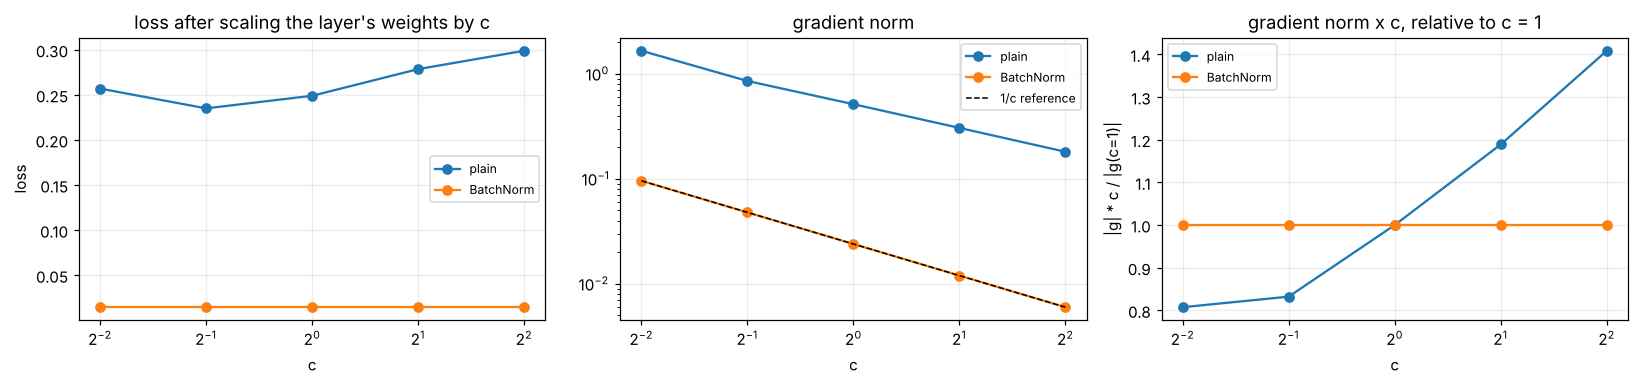

    c | plain loss  plain |g|  plain cos |  BN loss   BN |g|  BN |g|*c    BN cos
 0.25 |      0.257     1.6569     -0.011 |  0.01460   0.0956    0.0239  -7.9e-07
  0.5 |      0.235     0.8539     -0.001 |  0.01460   0.0478    0.0239  -1.9e-07
  1.0 |      0.249     0.5131      0.006 |  0.01460   0.0239    0.0239  -3.8e-08
  2.0 |      0.279     0.3050      0.004 |  0.01460   0.0120    0.0239  -1.2e-08
  4.0 |      0.299     0.1807      0.002 |  0.01460   0.0060    0.0239  -7.5e-09


In [8]:
def loss_and_grad(model, k, c):
    m = copy.deepcopy(model).train()
    W = m.blocks[k][0].weight
    with torch.no_grad():
        W.mul_(c)
    loss = loss_fn(m(PROBE_X), PROBE_Y)
    g, = torch.autograd.grad(loss, W)
    cos = F.cosine_similarity(g.flatten(), W.detach().flatten(), dim=0).item()
    return loss.item(), g.norm().item(), cos


cs = [0.25, 0.5, 1.0, 2.0, 4.0]
warm = {nm: new_model(nm) for nm in ("none", "bn")}
for m in warm.values():
    fit(m, epochs=5, lr=0.05)
inv = {nm: np.array([loss_and_grad(warm[nm], 3, c) for c in cs]) for nm in ("none", "bn")}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for nm, label in (("none", "plain"), ("bn", "BatchNorm")):
    axes[0].plot(cs, inv[nm][:, 0], marker="o", label=label)
    axes[1].plot(cs, inv[nm][:, 1], marker="o", label=label)
    axes[2].plot(cs, inv[nm][:, 1] * np.array(cs) / inv[nm][2, 1], marker="o", label=label)
axes[1].plot(cs, inv["bn"][2, 1] * 1.0 / np.array(cs), "k--", lw=1, label="1/c reference")
axes[0].set_title("loss after scaling the layer's weights by c"); axes[0].set_ylabel("loss")
axes[1].set_title("gradient norm"); axes[1].set_yscale("log")
axes[2].set_title("gradient norm x c, relative to c = 1"); axes[2].set_ylabel("|g| * c / |g(c=1)|")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xlabel("c"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'c':>5} | {'plain loss':>10} {'plain |g|':>10} {'plain cos':>10} | {'BN loss':>8} {'BN |g|':>8} {'BN |g|*c':>9} {'BN cos':>9}")
for i, c in enumerate(cs):
    p, bnr = inv["none"][i], inv["bn"][i]
    print(f"{c:>5} | {p[0]:>10.3f} {p[1]:>10.4f} {p[2]:>10.3f} | {bnr[0]:>8.5f} {bnr[1]:>8.4f} {bnr[1] * c:>9.4f} {bnr[2]:>9.1e}")

**What to notice.** With BatchNorm, the loss is **identical** at every scale (0.01460 in the table, to the digits shown), and `|g| * c` is a constant: the gradient shrinks exactly like `1/c`, the dashed reference line in the middle panel. The cosine between gradient and weights is zero to within about `1e-7`. In the plain network the loss changes (0.235 to 0.299) and `|g| * c` drifts by almost a factor of two.

A caution about reading the table: the cosine for the *plain* network is also tiny (about 0.01). That is not a sign of invariance, only that the weight matrix is large compared with the way the loss changes along it, so the cosine is a weak test and the exact constancy of the loss and of `|g| * c` is the real signature.

Why does this matter for training? Since the gradient is perpendicular to `W`, each SGD step *increases* `||W||` (by roughly `lr * ||g||` added at a right angle), and a larger `||W||` then shrinks the gradient and, relative to the weights, the effective step size. So BN gives each layer a built-in **self-tuning learning rate**. We will see the weight norm grow in section 5c.

## 5. Training with and without BatchNorm

Now we train and look at what changes.

### 5a. Watching the drift disappear

Both networks train at `lr = 0.1`. For the output of blocks 2, 4, 6 and 8 (each the input of the following layer) we track the mean absolute unit mean and the mean unit standard deviation on the fixed probe batch. Flat lines mean a layer sees a stable input.

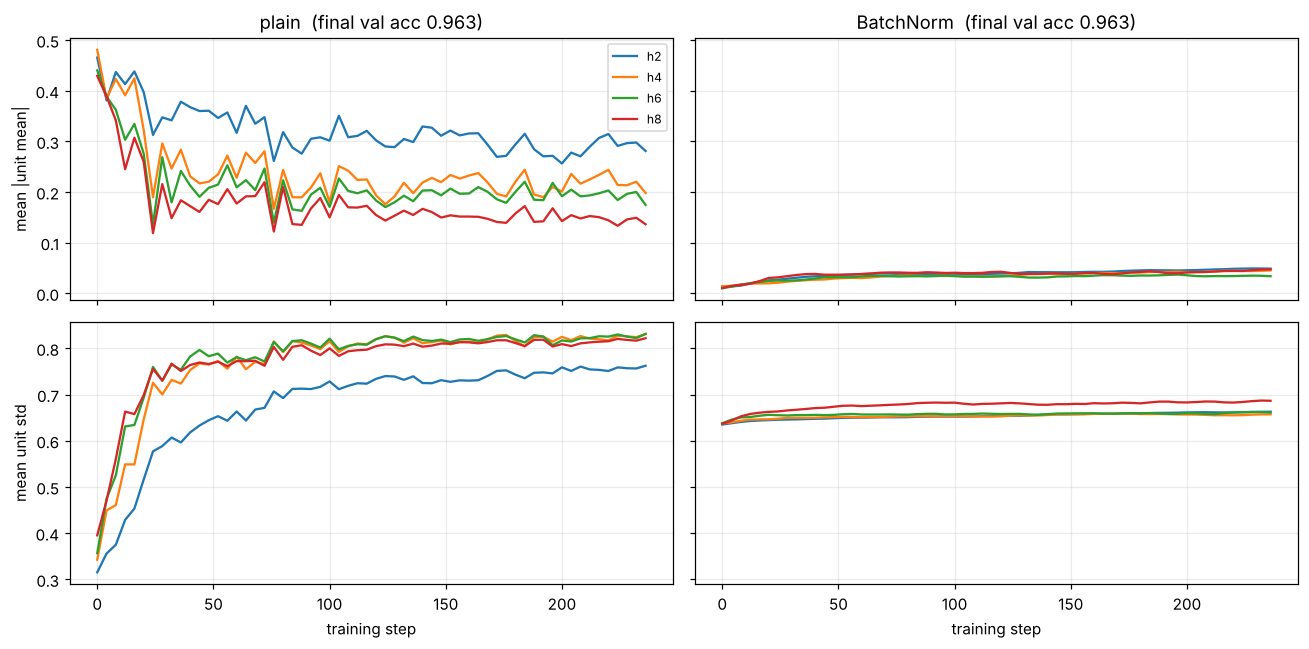

drift score (mean movement of a unit's mean between probes, in units of its std):
   plain      0.1395
   BatchNorm  0.0077


In [9]:
LR_OBS = 0.1
obs = {nm: fit(new_model(nm), epochs=15, lr=LR_OBS, probe_every=4) for nm in ("none", "bn")}

sel = [2, 4, 6, 8]
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey="row")
for col, (nm, label) in enumerate((("none", "plain"), ("bn", "BatchNorm"))):
    o = obs[nm]; steps = np.array(o["probe_steps"]); mu = np.stack(o["probe_mu"]); sd = np.stack(o["probe_sd"])
    for L in sel:
        axes[0, col].plot(steps, np.abs(mu[:, L - 1, :]).mean(1), label=f"h{L}")
        axes[1, col].plot(steps, sd[:, L - 1, :].mean(1), label=f"h{L}")
    axes[0, col].set_title(f"{label}  (final val acc {o['val_acc'][-1]:.3f})"); axes[1, col].set_xlabel("training step")
axes[0, 0].set_ylabel("mean |unit mean|"); axes[1, 0].set_ylabel("mean unit std"); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()


def drift_score(o):
    mu, sd = np.stack(o["probe_mu"]), np.stack(o["probe_sd"])
    return (np.abs(np.diff(mu, axis=0)) / (sd.mean(0)[None] + 1e-6)).mean()


print("drift score (mean movement of a unit's mean between probes, in units of its std):")
for nm, label in (("none", "plain"), ("bn", "BatchNorm")):
    print(f"   {label:<10} {drift_score(obs[nm]):.4f}")

**What to notice.** The plain network's layer inputs *move*: during the first 25 to 50 steps their mean magnitude falls from about 0.45 to between 0.15 and 0.30 depending on the layer, and their spread rises from 0.3 to 0.4 up to 0.75 to 0.83. Every layer is learning on an input that is changing under it. Under BN, the unit means stay below 0.05 and the spread sits at 0.64 to 0.69 for the whole run. The drift score drops from 0.140 to 0.008, about **18 times less drift**.

Notice also what is *not* different: at this learning rate both networks end at the same validation accuracy (0.963). Removing drift does not by itself make a network more accurate. The next two sections look at what else changes.

### 5b. A free lunch at initialization: the signal stays healthy at any weight scale

Before any training, push the probe batch through networks whose hidden weights are initialized at 0.25x, 1x and 4x the recommended scale. For each block output we plot the spread of the activations and the fraction of saturated `tanh` units.

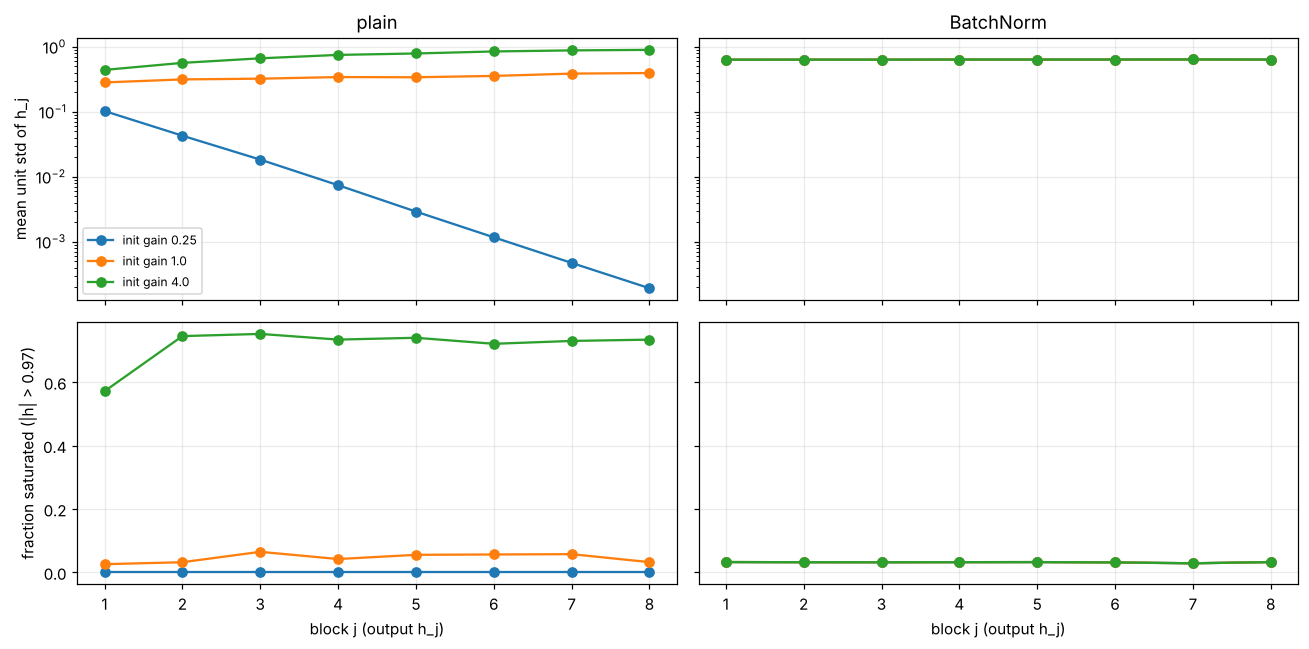

In [10]:
gains = [0.25, 1.0, 4.0]
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey="row")
for col, (nm, label) in enumerate((("none", "plain"), ("bn", "BatchNorm"))):
    for gnum in gains:
        m = new_model(nm, init_gain=gnum).train()
        with torch.no_grad():
            _, hs = m(PROBE_X, return_acts=True)
        axes[0, col].plot(range(1, 9), [h.std(0).mean().item() for h in hs[1:]], marker="o", label=f"init gain {gnum}")
        axes[1, col].plot(range(1, 9), [(h.abs() > 0.97).float().mean().item() for h in hs[1:]], marker="o", label=f"init gain {gnum}")
    axes[0, col].set_title(label); axes[1, col].set_xlabel("block j (output h_j)")
axes[0, 0].set_ylabel("mean unit std of h_j"); axes[0, 0].set_yscale("log")
axes[1, 0].set_ylabel("fraction saturated (|h| > 0.97)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice.** For the plain network the weight scale at initialization decides everything. At 0.25x the signal **vanishes**: the activation spread shrinks by about 0.45x per block, from 0.1 after block 1 to 0.0002 after block 8, so the output layer sees almost the same input for every example. At 4x the opposite happens: between 57% and 75% of the units are saturated from the first block on, which means tiny gradients through those units. Only the recommended 1x scale keeps the signal healthy (3% to 6% saturated).

With BN the three initializations give **the same curve**, to within the line width: spread about 0.63, about 3% saturated, at every depth. This is the scale invariance of section 4b seen from the forward side: since each block re-standardizes its input, the scale of the weights it was given cannot matter.

### 5c. Speed, learning-rate tolerance and initialization robustness

Two sweeps, 15 epochs each, 2 seeds per setting, SGD with momentum 0.9:

- **learning rate** from 0.01 to 1.0, with the standard initialization
- **initialization scale** from 0.25x to 4x, at `lr = 0.05`

We report validation accuracy at the end. Chance level is 0.10, and that is where a run that blows up or stalls ends up.

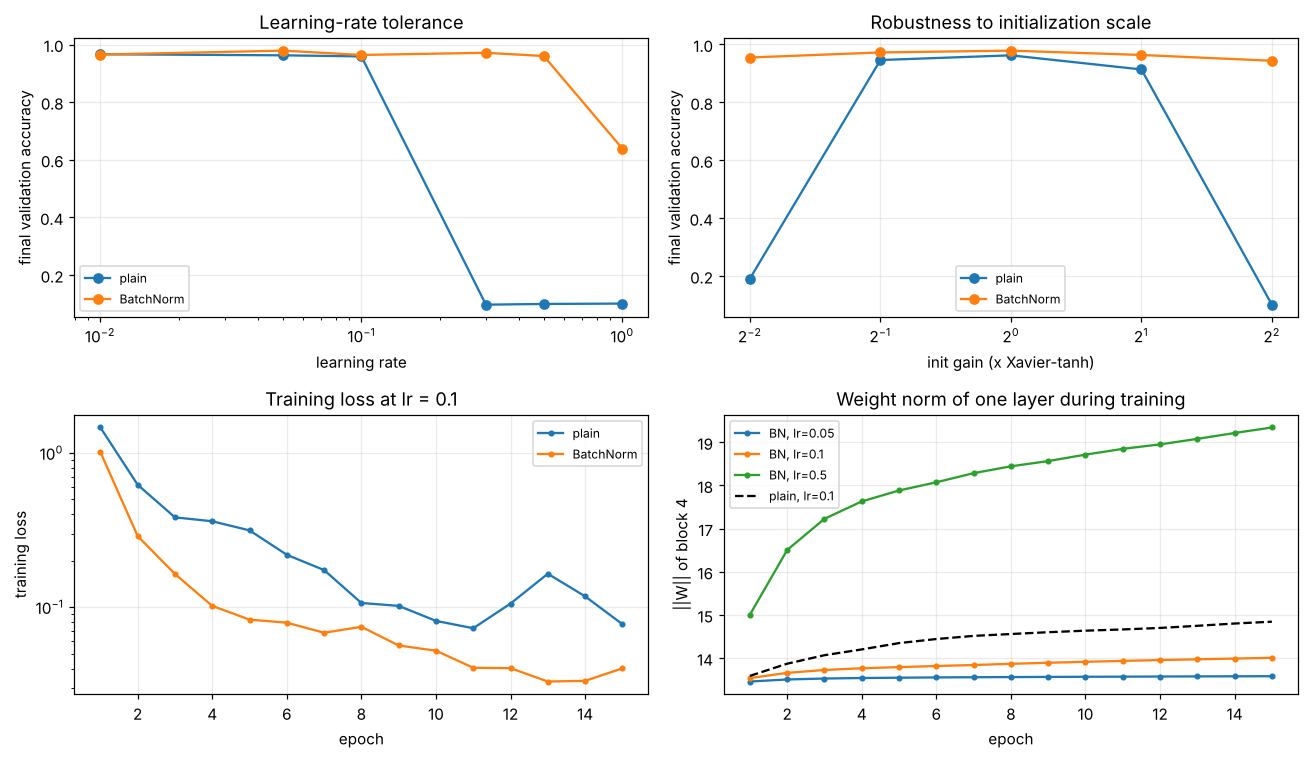

Final validation accuracy (mean of 2 seeds; chance = 0.10)
    lr |        plain           BN
  0.01 |        0.966        0.965
  0.05 |        0.962        0.979
   0.1 |        0.959        0.964
   0.3 |        0.098        0.971
   0.5 |        0.100        0.960
   1.0 |        0.101        0.639

  gain |        plain           BN
  0.25 |        0.191        0.955
   0.5 |        0.946        0.973
   1.0 |        0.962        0.979
   2.0 |        0.914        0.964
   4.0 |        0.101        0.944

Epochs to reach 90% validation accuracy (lr = 0.1): {'none': 3, 'bn': 2}


In [11]:
EPOCHS = 15
LRS = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]
GAINS = [0.25, 0.5, 1.0, 2.0, 4.0]
SEEDS = (0, 1)

lr_runs = {(nm, lr): [fit(new_model(nm, seed=s), epochs=EPOCHS, lr=lr, seed=s) for s in SEEDS]
           for nm in ("none", "bn") for lr in LRS}
gain_runs = {(nm, gn): [fit(new_model(nm, seed=s, init_gain=gn), epochs=EPOCHS, lr=0.05, seed=s) for s in SEEDS]
             for nm in ("none", "bn") for gn in GAINS}

final_acc = lambda runs: np.mean([r["val_acc"][-1] for r in runs])

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for nm, label in (("none", "plain"), ("bn", "BatchNorm")):
    axes[0, 0].plot(LRS, [final_acc(lr_runs[(nm, lr)]) for lr in LRS], marker="o", label=label)
    axes[0, 1].plot(GAINS, [final_acc(gain_runs[(nm, gn)]) for gn in GAINS], marker="o", label=label)
    axes[1, 0].plot(range(1, EPOCHS + 1), np.mean([r["train_loss"] for r in lr_runs[(nm, 0.1)]], 0), marker="o", ms=3, label=label)
for lr in (0.05, 0.1, 0.5):
    axes[1, 1].plot(range(1, EPOCHS + 1), np.mean([r["wnorm"] for r in lr_runs[("bn", lr)]], 0), marker="o", ms=3, label=f"BN, lr={lr}")
axes[1, 1].plot(range(1, EPOCHS + 1), np.mean([r["wnorm"] for r in lr_runs[("none", 0.1)]], 0), "k--", label="plain, lr=0.1")
axes[0, 0].set_xscale("log"); axes[0, 0].set_xlabel("learning rate"); axes[0, 0].set_ylabel("final validation accuracy")
axes[0, 0].set_title("Learning-rate tolerance")
axes[0, 1].set_xscale("log", base=2); axes[0, 1].set_xlabel("init gain (x Xavier-tanh)"); axes[0, 1].set_ylabel("final validation accuracy")
axes[0, 1].set_title("Robustness to initialization scale")
axes[1, 0].set_yscale("log"); axes[1, 0].set_xlabel("epoch"); axes[1, 0].set_ylabel("training loss"); axes[1, 0].set_title("Training loss at lr = 0.1")
axes[1, 1].set_xlabel("epoch"); axes[1, 1].set_ylabel("||W|| of block 4"); axes[1, 1].set_title("Weight norm of one layer during training")
for ax in axes.flat: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Final validation accuracy (mean of 2 seeds; chance = 0.10)")
print(f"{'lr':>6} | {'plain':>12} {'BN':>12}")
for lr in LRS:
    print(f"{lr:>6} | {final_acc(lr_runs[('none', lr)]):>12.3f} {final_acc(lr_runs[('bn', lr)]):>12.3f}")
print(f"\n{'gain':>6} | {'plain':>12} {'BN':>12}")
for gn in GAINS:
    print(f"{gn:>6} | {final_acc(gain_runs[('none', gn)]):>12.3f} {final_acc(gain_runs[('bn', gn)]):>12.3f}")


def epochs_to(acc, runs):
    m = np.mean([r["val_acc"] for r in runs], 0)
    hit = np.where(m >= acc)[0]
    return int(hit[0]) + 1 if len(hit) else None


print("\nEpochs to reach 90% validation accuracy (lr = 0.1):",
      {nm: epochs_to(0.9, lr_runs[(nm, 0.1)]) for nm in ("none", "bn")})

**What to notice.**

- **Learning-rate tolerance.** At small rates (0.01) BN and plain are equivalent (0.965 and 0.966): BN is not faster or better there. The plain network works up to `lr = 0.1` and then collapses to chance (0.10) at 0.3, 0.5 and 1.0. BN trains normally at 0.3 and 0.5 (0.971 and 0.960), a rate at least 3 to 5 times higher than the plain network can survive here. BN is not unlimited, though: at `lr = 1.0` it degrades too (0.64).
- **Initialization.** The plain network fails at both ends of the range, at 0.25x (0.19) and at 4x (0.10), and is already worse at 2x (0.91). BN stays between 0.944 and 0.979 across a **16-fold** range of initial weight scale, which is what section 5b predicted.
- **Speed.** At `lr = 0.1` BN has the lower training loss at almost every epoch and its curve is smoother (the plain curve has a bump around epochs 12 to 13), and BN reaches 90% validation accuracy in 2 epochs against 3. The speed-up is real but modest on this small, easy problem; BN's headline gains are in what it allows (higher rates, careless initialization), not in a dramatic head start at a rate that already suits the plain network.
- **Weight norm.** The BN layer's weight norm only grows, and it grows faster the larger the learning rate: from 15 to 19.4 at `lr = 0.5`, but almost flat (13.5 to 13.6) at `lr = 0.05`. This is consistent with the mechanism in section 4b: a large step pushes the weights outward, which automatically shrinks the effective step size and keeps training stable. (SGD with momentum is not exactly a sequence of orthogonal steps, so read this as consistent with the mechanism rather than a proof.)

With two seeds per setting, differences of about 0.01 in accuracy are within noise; the large gaps above are not.

## 6. The price: BatchNorm depends on the batch

In training, every example is normalized with statistics computed from **its own mini-batch**, so its output depends on which other examples happen to be in the batch. At test time we replace those with **running averages**. This split is the source of most practical BN problems. We train a BN network (20 epochs, `lr = 0.05`) and examine it.

### 6a. Do the running statistics match the real ones?

For three layers we compare the running mean/variance stored by BN with the statistics of that layer's input over the whole training set (computed in one big batch).

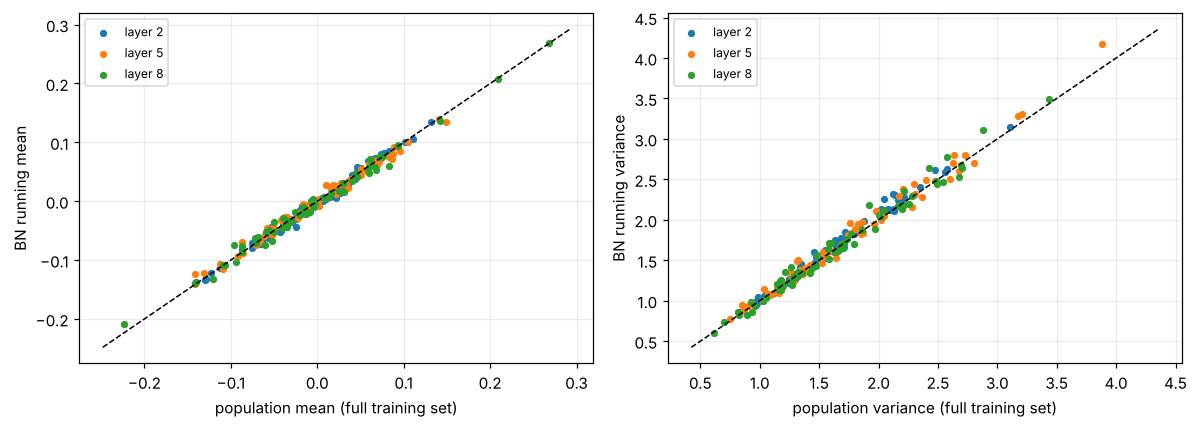

mean relative error of running variance, per layer: [0.022 0.031 0.031 0.036 0.038 0.035 0.038 0.039]


In [12]:
bn_model = new_model("bn")
fit(bn_model, epochs=20, lr=0.05)

# population statistics: forward the entire training set as ONE batch in a copy, capturing each BN layer's input
pop, hooks = {}, []
cp = copy.deepcopy(bn_model).train()
for k, blk in enumerate(cp.blocks):
    hooks.append(blk[1].register_forward_hook(lambda mod, inp, out, k=k: pop.__setitem__(k, (inp[0].mean(0).detach(), inp[0].var(0, unbiased=False).detach()))))
with torch.no_grad():
    cp(Xtr_t)
for hk in hooks: hk.remove()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, col in zip((1, 4, 7), ("C0", "C1", "C2")):
    rm, rv = bn_model.blocks[k][1].running_mean, bn_model.blocks[k][1].running_var
    axes[0].scatter(pop[k][0], rm, s=14, color=col, label=f"layer {k + 1}")
    axes[1].scatter(pop[k][1], rv, s=14, color=col, label=f"layer {k + 1}")
for ax, t in zip(axes, ("mean", "variance")):
    lim = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, "k--", lw=1); ax.set_xlabel(f"population {t} (full training set)"); ax.set_ylabel(f"BN running {t}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

rel = [((bn_model.blocks[k][1].running_var - pop[k][1]).abs() / pop[k][1]).mean().item() for k in range(8)]
print("mean relative error of running variance, per layer:", np.round(rel, 3))

**What to notice.** The running statistics land on the diagonal: the running mean tracks the population mean, and the running variance is within 2% to 4% (mean relative error per layer) of the variance over the full training set. This is why `eval()` mode works: the validation accuracy in `eval()` mode below (0.973) is the best we measure. The small gap is the price of an exponential average that lags a slowly moving network, with default momentum 0.1.

### 6b. Batch-dependence at inference

If someone forgets `model.eval()` (or you deliberately use batch statistics at test time), predictions depend on the batch composition. Two measurements on the validation set:

1. accuracy using **batch statistics** with different batch sizes, against `eval()` mode (running statistics)
2. for one fixed validation example, how much its output logit moves when it is placed in different random batches

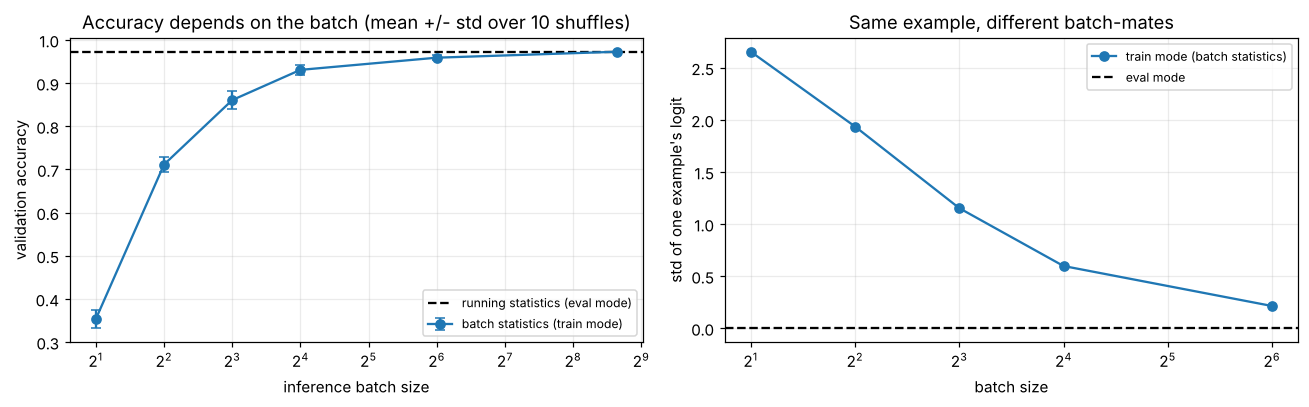

val acc, batch statistics: {2: np.float64(0.354), 4: np.float64(0.711), 8: np.float64(0.86), 16: np.float64(0.93), 64: np.float64(0.959), 400: np.float64(0.972)} | eval mode: 0.973


In [13]:
@torch.no_grad()
def val_acc_batches(model, bs, mode, seed):
    m = copy.deepcopy(model)
    m.train() if mode == "batch" else m.eval()
    perm = torch.randperm(len(Xva_t), generator=torch.Generator().manual_seed(seed))
    correct = n = 0
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        if len(idx) < 2 and mode == "batch":
            continue
        correct += (m(Xva_t[idx]).argmax(1) == yva_t[idx]).sum().item(); n += len(idx)
    return correct / n


BS = [2, 4, 8, 16, 64, 400]
acc_batch = np.array([[val_acc_batches(bn_model, bs, "batch", s) for s in range(10)] for bs in BS])
acc_eval = val_acc_batches(bn_model, 64, "eval", 0)

# logit of the true class for ONE example placed into random batches
@torch.no_grad()
def logit_spread(model, bs, n_batches=300, idx0=0):
    m = copy.deepcopy(model).train()
    rng = np.random.default_rng(0)
    others = np.setdiff1d(np.arange(len(Xva_t)), [idx0])
    vals = []
    for _ in range(n_batches):
        idx = np.concatenate([[idx0], rng.choice(others, bs - 1, replace=False)])
        vals.append(m(Xva_t[idx])[0, int(yva_t[idx0])].item())
    return np.std(vals)


BS2 = [2, 4, 8, 16, 64]
spread = [logit_spread(bn_model, bs) for bs in BS2]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].errorbar(BS, acc_batch.mean(1), yerr=acc_batch.std(1), marker="o", capsize=3, label="batch statistics (train mode)")
axes[0].axhline(acc_eval, color="k", ls="--", label="running statistics (eval mode)")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("inference batch size"); axes[0].set_ylabel("validation accuracy"); axes[0].legend(fontsize=8)
axes[0].set_title("Accuracy depends on the batch (mean +/- std over 10 shuffles)")
axes[1].plot(BS2, spread, marker="o", label="train mode (batch statistics)"); axes[1].axhline(0, color="k", ls="--", label="eval mode")
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("batch size"); axes[1].set_ylabel("std of one example's logit")
axes[1].set_title("Same example, different batch-mates"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("val acc, batch statistics:", dict(zip(BS, acc_batch.mean(1).round(3))), "| eval mode:", round(acc_eval, 3))

**What to notice.** If you leave a BN network in train mode at inference (a classic bug) the predictions depend on **who else is in the batch**. With batch statistics the validation accuracy is 0.35 at batch size 2, 0.71 at 4, 0.86 at 8, 0.93 at 16 and 0.96 at 64, and only approaches the `eval()`-mode value of 0.973 once the batch is large enough to estimate the population statistics (0.972 at 400). The right panel shows it on a single example: at batch size 2, the same input's logit has a standard deviation of about 2.6 depending on its batch-mates; in `eval()` mode it is exactly zero. (A batch of one is not even defined in train mode, since a single value has no variance.)

### 6c. Small training batches make the statistics noisy

During training, `mu_B` and `var_B` are noisy estimates of the real statistics, and the noise grows as the batch shrinks. We train plain and BN networks with different batch sizes (15 epochs, 2 seeds) and evaluate in `eval()` mode. A fixed learning rate would confound the comparison (small batches mean many more, noisier steps), so we scale it with the batch size, `lr = 0.05 * batch / 64` capped at 0.1, which keeps the plain network stable at every size.

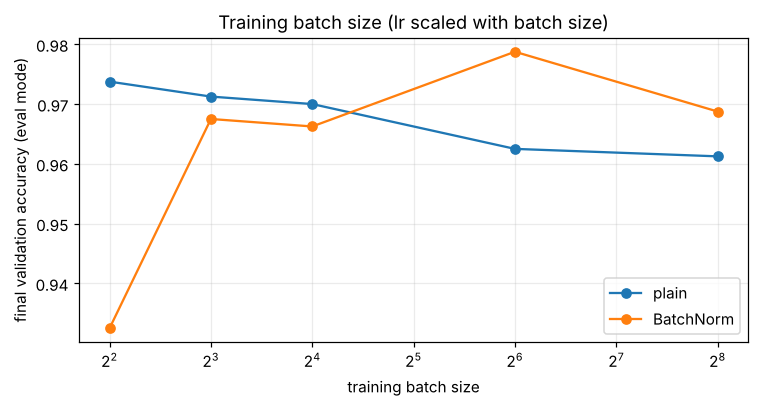

 batch       lr |    plain       BN
     4   0.0031 |    0.974    0.933
     8   0.0063 |    0.971    0.968
    16   0.0125 |    0.970    0.966
    64   0.0500 |    0.962    0.979
   256   0.1000 |    0.961    0.969


In [14]:
TRAIN_BS = [4, 8, 16, 64, 256]
lr_for = lambda bs: min(0.1, 0.05 * bs / 64)
bs_runs = {(nm, bs): [fit(new_model(nm, seed=s), epochs=15, lr=lr_for(bs), batch_size=bs, seed=s) for s in SEEDS]
           for nm in ("none", "bn") for bs in TRAIN_BS}
fig, ax = plt.subplots(figsize=(7, 3.8))
for nm, label in (("none", "plain"), ("bn", "BatchNorm")):
    ax.plot(TRAIN_BS, [final_acc(bs_runs[(nm, bs)]) for bs in TRAIN_BS], marker="o", label=label)
ax.set_xscale("log", base=2); ax.set_xlabel("training batch size"); ax.set_ylabel("final validation accuracy (eval mode)"); ax.legend()
ax.set_title("Training batch size (lr scaled with batch size)")
plt.tight_layout(); plt.show()
print(f"{'batch':>6} {'lr':>8} | {'plain':>8} {'BN':>8}")
for bs in TRAIN_BS:
    print(f"{bs:>6} {lr_for(bs):>8.4f} | {final_acc(bs_runs[('none', bs)]):>8.3f} {final_acc(bs_runs[('bn', bs)]):>8.3f}")

**What to notice.** With the learning rate scaled to the batch size, plain and BN are within about 0.01 of each other from batch size 8 up (0.968 vs 0.971 at 8, 0.966 vs 0.970 at 16; BN is best at 64: 0.979 vs 0.962), which is inside the noise for 2 seeds. At **batch size 4** BN falls behind (0.933 against 0.974): the batch statistics are estimated from four examples, so each step normalizes with a noisy `mu_B` and `var_B`, and the running averages used at test time no longer match what the network trained on. This is the practical weakness of BatchNorm, and the motivation for batch-independent alternatives (LayerNorm, GroupNorm), which compute their statistics per example.

## 7. Does BatchNorm "solve" internal covariate shift?

**What BatchNorm does, mechanically.** It standardizes each unit's pre-activation over the mini-batch, then applies a learned scale `gamma` and shift `beta`. In training it uses batch statistics (and keeps running averages); at inference it uses the running averages.

**The ICS claim, as far as this notebook can test it.**

1. **BN does pin each layer's input statistics.** Section 3 shows that the mean and variance of a layer's input become independent of the preceding weights (rescaling, bias shifts and random changes leave them untouched), and section 5a shows about 18 times less drift during real training. In that narrow sense it removes the *moving target* from layer `k`'s point of view.
2. **But that is not the whole mechanism, and probably not the main one.** BN also makes every layer scale-invariant (4b), which gives self-tuning effective learning rates (5c, weight norm), keeps activations in a healthy range at any initialization (5b), and the previous notebook showed that **re-injecting random shift after BN does not destroy its benefits** and that the loss landscape becomes smoother. So "BN helps because it reduces ICS" is at best incomplete: a network can have a lot of internal shift and still enjoy BN's learning-rate tolerance.
3. **BN is not free.** It couples the examples in a batch, behaves differently in train and eval, and gets worse with very small batches (section 6).

**Practical notes**

- Put BN between the linear (or conv) layer and the nonlinearity as here, and drop the bias in front of it (it is cancelled). Placing it after the activation also works in practice, and there is no universal winner.
- Always call `model.eval()` for inference, and `model.train()` again before training.
- With small batches (a few examples per device), or batch-dependent behaviour you cannot accept, consider LayerNorm or GroupNorm, or freeze the BN statistics when fine-tuning with small batches.
- Because BN layers are scale-invariant, weight decay on the weights in front of them acts mainly by controlling the effective learning rate (the weight norm), not by shrinking the function.

**Try it yourself**

1. Change BN's `momentum` to 0.01 and to 0.9 and redo the running-versus-population plot in 6a: what goes wrong at each extreme?
2. Use `affine=False` (fix `gamma = 1`, `beta = 0`) and rerun section 5c. How much of the benefit survives?
3. Move BN after the `tanh` and rerun sections 5a to 5c.
4. Replace `BatchNorm1d` with `LayerNorm` and repeat 6b and 6c. What changes at small batch sizes?
5. Add weight decay in `fit` and watch the weight-norm plot in 5c.